# DWD-Wetterdaten Berlin ab 2020

Dieses Notebook lädt ausschließlich tägliche DWD-Messwerte als CSV herunter. Es führt noch keine Wetteranalyse durch.

**Station:** Berlin-Dahlem (FU), DWD-ID `00403`, nahe Berlin-Zentrum. **Quelle:** DWD Climate Data Center, Tageswerte (KL). Der Download kombiniert die historische Datei bis 2025-12-31 mit der aktuellen Datei ab 2026 und reicht bis zum jüngsten dort verfügbaren Messdatum.

## Verfügbarkeit der Messgrößen

Die Stationsmetadaten weisen alle angeforderten Messgrößen bis zum **01.11.2026** aus: `TNK` (Tagesminimum, °C), `TXK` (Tagesmaximum, °C), `TMK` (Tagesmittel, °C), `RSK` (Niederschlagssumme, mm) und `SDK` (Sonnenscheindauer, Stunden).

Im Zeitraum 2020-01-01 bis 2026-11-01 liegen 2.483 Tagesdatensätze für 2.497 Kalendertage vor. Vom **04.03. bis 17.03.2025** fehlt ein kompletter Datensatz; außerdem gibt es vereinzelt fehlende Einzelwerte. Der Export ergänzt alle Kalendertage und schreibt fehlende Messwerte als leere CSV-Felder. Damit sind die Daten verfügbar, aber nicht lückenlos.

### Spalten und Quellen

| CSV-Spalte | DWD-Feld | Bedeutung | Einheit |
| --- | --- | --- | --- |
| `temp_min_c` | `TNK` | Tagesminimum in 2 m Höhe | °C |
| `temp_max_c` | `TXK` | Tagesmaximum in 2 m Höhe | °C |
| `temp_durchschnitt_c` | `TMK` | Tagesmitteltemperatur | °C |
| `niederschlag_mm` | `RSK` | tägliche Niederschlagssumme | mm |
| `sonnenstunden_h` | `SDK` | tägliche Sonnenscheindauer | h |

Historische Daten: [DWD-Archiv Berlin-Dahlem](https://opendata.dwd.de/climate_environment/CDC/observations_germany/climate/daily/kl/historical/). Aktuelle Daten: [DWD-Recent Berlin-Dahlem](https://opendata.dwd.de/climate_environment/CDC/observations_germany/climate/daily/kl/recent/). Der DWD-Kennwert `-999` wird als fehlender Wert exportiert.

In [1]:
import csv
import io
import urllib.request
import zipfile
from datetime import date, datetime, timedelta
from pathlib import Path

## CSV herunterladen

Die folgende Zelle lädt die DWD-Historie und die aktuelle Tagesdatei, kombiniert sie ohne doppelte Tage und speichert eine CSV im aktuellen Notebook-Arbeitsverzeichnis. Für jeden Kalendertag ab 2020-01-01 gibt es eine Zeile; fehlende Messungen bleiben leer.

In [2]:
dwd_base_url = (
    "https://opendata.dwd.de/climate_environment/CDC/observations_germany/"
    "climate/daily/kl/"
 )
historical_url = (
    dwd_base_url
    + "historical/tageswerte_KL_00403_19500101_20251231_hist.zip"
 )
recent_url = dwd_base_url + "recent/tageswerte_KL_00403_akt.zip"
start_date = date(2020, 1, 1)
today = date.today()

def read_dwd_product(url):
    with urllib.request.urlopen(url, timeout=60) as response:
        archive_bytes = response.read()

    with zipfile.ZipFile(io.BytesIO(archive_bytes)) as archive:
        product_name = next(
            name
            for name in archive.namelist()
            if name.startswith("produkt_klima_tag_") and name.endswith(".txt")
        )
        product_text = archive.read(product_name).decode("latin-1")

    reader = csv.DictReader(io.StringIO(product_text), delimiter=";")
    return [
        {
            key.strip(): (value or "").strip()
            for key, value in row.items()
            if key
        }
        for row in reader
    ]

def get_measurement_date(row):
    value = row.get("MESS_DATUM", "")
    try:
        return datetime.strptime(value, "%Y%m%d").date()
    except ValueError:
        return None

historical_rows = read_dwd_product(historical_url)
recent_rows = read_dwd_product(recent_url)
historical_by_date = {}

for row in historical_rows:
    measurement_date = get_measurement_date(row)
    if measurement_date is not None and start_date <= measurement_date <= today:
        historical_by_date[measurement_date] = row

if not historical_by_date:
    raise ValueError("Die DWD-Historie enthält keine Daten ab 2020.")

historical_end = max(historical_by_date)
records_by_date = historical_by_date.copy()

for row in recent_rows:
    measurement_date = get_measurement_date(row)
    if (
        measurement_date is not None
        and historical_end < measurement_date <= today
    ):
        records_by_date[measurement_date] = row

latest_date = max(records_by_date)
if latest_date < start_date:
    raise ValueError("Die DWD-Dateien enthalten keine Daten ab 2020.")

column_map = {
    "temp_min_c": "TNK",
    "temp_max_c": "TXK",
    "temp_durchschnitt_c": "TMK",
    "niederschlag_mm": "RSK",
    "sonnenstunden_h": "SDK",
}
csv_columns = ["datum", *column_map.keys()]
csv_rows = []
missing_record_dates = []
current_date = start_date

while current_date <= latest_date:
    source_row = records_by_date.get(current_date)
    if source_row is None:
        missing_record_dates.append(current_date)

    output_row = {"datum": current_date.isoformat()}
    for output_column, dwd_column in column_map.items():
        value = source_row.get(dwd_column, "") if source_row else ""
        try:
            is_missing = not value or float(value) == -999
        except ValueError:
            is_missing = True
        output_row[output_column] = "" if is_missing else value

    csv_rows.append(output_row)
    current_date += timedelta(days=1)

csv_path = Path.cwd() / "dwd_berlin_dahlem_2020_bis_heute.csv"
with csv_path.open("w", newline="", encoding="utf-8") as csv_file:
    writer = csv.DictWriter(csv_file, fieldnames=csv_columns)
    writer.writeheader()
    writer.writerows(csv_rows)

print("Station: Berlin-Dahlem (FU), DWD-ID 00403")
print(f"Zeitraum: {start_date} bis {latest_date}")
print(f"Tageszeilen: {len(csv_rows)}; fehlende komplette Tage: {len(missing_record_dates)}")
if missing_record_dates:
    print(
        "Lückenzeitraum: "
        f"{min(missing_record_dates)} bis {max(missing_record_dates)}"
    )
for output_column in column_map:
    missing_count = sum(not row[output_column] for row in csv_rows)
    print(f"Fehlende Werte {output_column}: {missing_count}")
print(f"CSV gespeichert unter: {csv_path.resolve()}")

Station: Berlin-Dahlem (FU), DWD-ID 00403
Zeitraum: 2020-01-01 bis 2026-11-01
Tageszeilen: 2497; fehlende komplette Tage: 14
Lückenzeitraum: 2025-03-04 bis 2025-03-17
Fehlende Werte temp_min_c: 16
Fehlende Werte temp_max_c: 16
Fehlende Werte temp_durchschnitt_c: 16
Fehlende Werte niederschlag_mm: 15
Fehlende Werte sonnenstunden_h: 16
CSV gespeichert unter: /workspaces/seminar3/dwd_berlin_dahlem_2020_bis_heute.csv


## Durchschnittstemperatur im Jahresvergleich

Die Tagesmitteltemperatur wird für jedes Jahr als eigene farbige Linie über einen gemeinsamen Kalenderverlauf gelegt. Der 29. Februar bleibt bei Schaltjahren enthalten; fehlende DWD-Werte erscheinen als Lücken. Das jüngste Jahr ist unvollständig und reicht nur bis zum neuesten CSV-Datum.

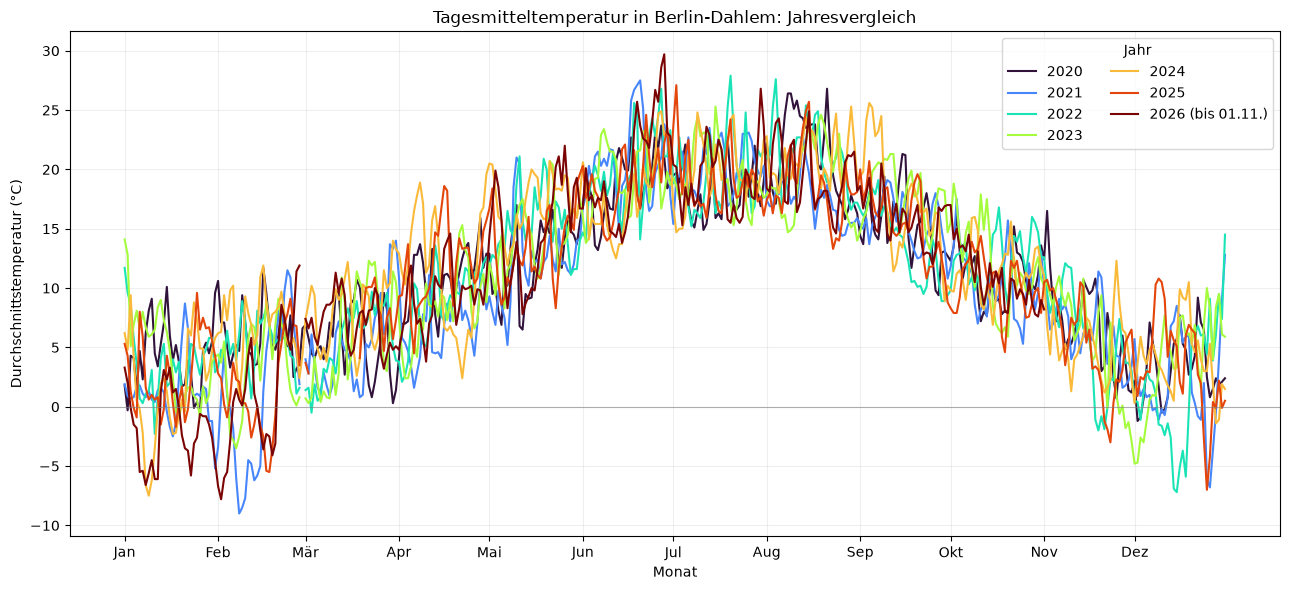

In [3]:
import csv
from datetime import datetime, timedelta
from pathlib import Path

import matplotlib.pyplot as plt

csv_path = Path.cwd() / "dwd_berlin_dahlem_2020_bis_heute.csv"
annual_temperatures = {}
latest_csv_date = None

with csv_path.open("r", newline="", encoding="utf-8") as csv_file:
    for row in csv.DictReader(csv_file):
        measurement_date = datetime.strptime(row["datum"], "%Y-%m-%d")
        latest_csv_date = measurement_date
        calendar_day = datetime(2000, measurement_date.month, measurement_date.day)
        temperature_value = row["temp_durchschnitt_c"].strip()
        annual_temperatures.setdefault(measurement_date.year, {})[calendar_day] = (
            float(temperature_value) if temperature_value else float("nan")
        )

if not annual_temperatures:
    raise ValueError(f"Keine Temperaturdaten in {csv_path.resolve()}")

years = sorted(annual_temperatures)
calendar_days = [datetime(2000, 1, 1) + timedelta(days=day) for day in range(366)]
color_positions = [index / max(1, len(years) - 1) for index in range(len(years))]
colors = plt.cm.turbo(color_positions)

fig, ax = plt.subplots(figsize=(13, 6))
for year, color in zip(years, colors):
    temperatures = [
        annual_temperatures[year].get(calendar_day, float("nan"))
        for calendar_day in calendar_days
    ]
    label = str(year)
    if year == latest_csv_date.year and latest_csv_date.month < 12:
        label = f"{year} (bis {latest_csv_date:%d.%m.})"
    ax.plot(calendar_days, temperatures, label=label, color=color, linewidth=1.5)

ax.set_title("Tagesmitteltemperatur in Berlin-Dahlem: Jahresvergleich")
ax.set_xlabel("Monat")
ax.set_ylabel("Durchschnittstemperatur (°C)")
ax.set_xticks([datetime(2000, month, 1) for month in range(1, 13)])
ax.set_xticklabels(
    ["Jan", "Feb", "Mär", "Apr", "Mai", "Jun", "Jul", "Aug", "Sep", "Okt", "Nov", "Dez"]
 )
ax.axhline(0, color="gray", linewidth=0.8, alpha=0.6)
ax.grid(alpha=0.2)
ax.legend(title="Jahr", ncol=2)
fig.tight_layout()
plt.show()

Verglichene vollständige Jahre: [2020, 2021, 2022, 2023, 2024, 2025]
Mittlere tägliche Spannweite im Winter: 9.9 °C
Mittlere tägliche Spannweite im Sommer: 7.1 °C
Winter minus Sommer: +2.8 °C (+39 % gegenüber dem Sommer)


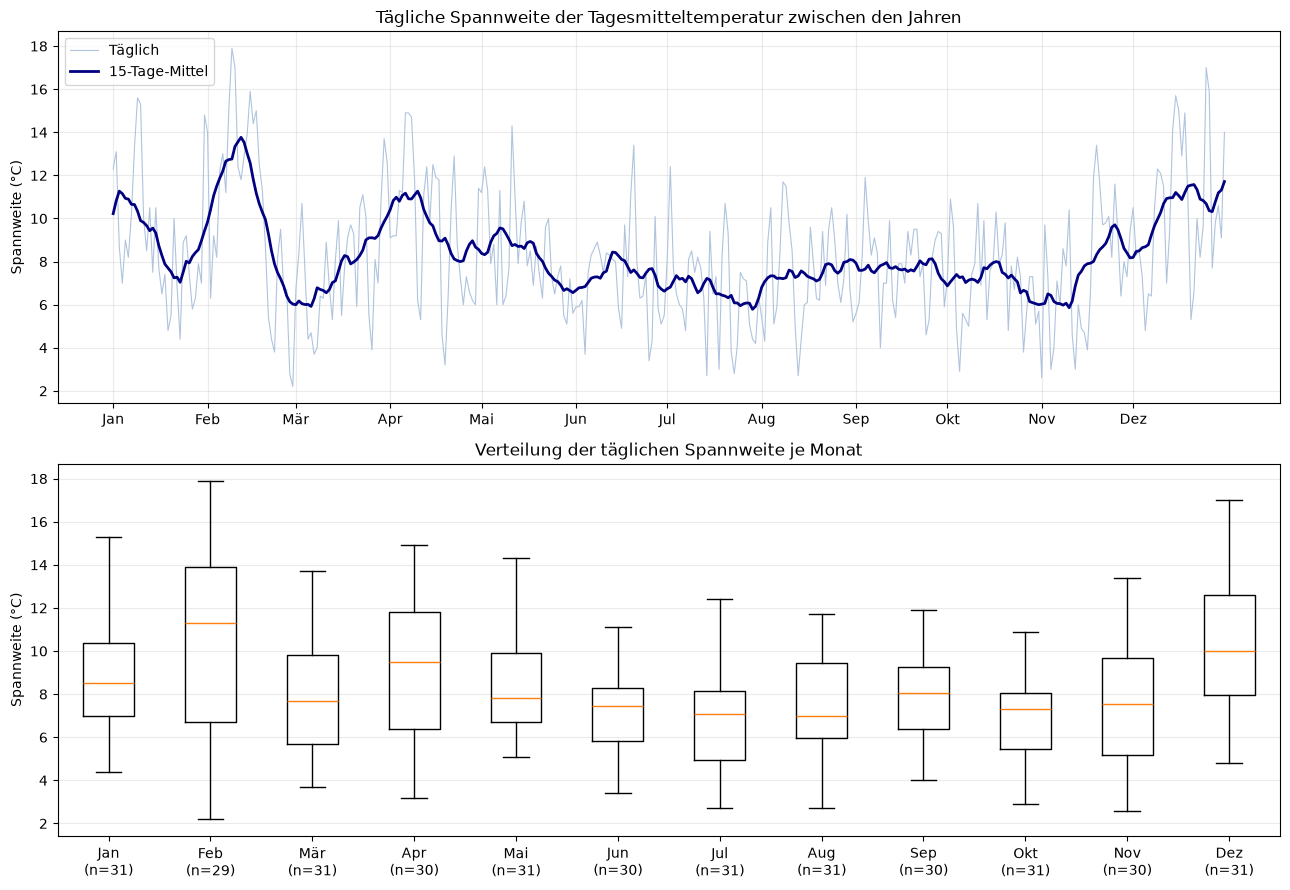

In [5]:
# Das jüngste Jahr ist unvollständig und wird für den fairen Vergleich ausgelassen.
complete_years = [year for year in years if year < latest_csv_date.year]
daily_ranges = []
monthly_ranges = {month: [] for month in range(1, 13)}

for index, calendar_day in enumerate(calendar_days):
    values = [
        annual_temperatures[year].get(calendar_day, float("nan"))
        for year in complete_years
    ]
    values = [value for value in values if value == value]  # NaN ausschließen

    if len(values) >= 2:
        spread = max(values) - min(values)
        daily_ranges.append((calendar_day, spread))
        monthly_ranges[calendar_day.month].append(spread)

winter_values = [
    spread
    for month in (12, 1, 2)
    for spread in monthly_ranges[month]
 ]
summer_values = [
    spread
    for month in (6, 7, 8)
    for spread in monthly_ranges[month]
 ]

winter_mean = sum(winter_values) / len(winter_values)
summer_mean = sum(summer_values) / len(summer_values)
difference = winter_mean - summer_mean
percent_difference = difference / summer_mean * 100 if summer_mean else float("nan")

print(f"Verglichene vollständige Jahre: {complete_years}")
print(f"Mittlere tägliche Spannweite im Winter: {winter_mean:.1f} °C")
print(f"Mittlere tägliche Spannweite im Sommer: {summer_mean:.1f} °C")
print(
    f"Winter minus Sommer: {difference:+.1f} °C "
    f"({percent_difference:+.0f} % gegenüber dem Sommer)"
 )

# 15-Tage-Mittel glättet die tägliche Spannweite für den Saisonverlauf.
smoothed_ranges = []
for index in range(len(daily_ranges)):
    window = daily_ranges[max(0, index - 7): index + 8]
    smoothed_ranges.append(
        sum(spread for _, spread in window) / len(window)
    )

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 9))

dates = [day for day, _ in daily_ranges]
spreads = [spread for _, spread in daily_ranges]
ax1.plot(dates, spreads, color="lightsteelblue", linewidth=0.8, label="Täglich")
ax1.plot(
    dates,
    smoothed_ranges,
    color="navy",
    linewidth=2,
    label="15-Tage-Mittel",
 )
ax1.set_title("Tägliche Spannweite der Tagesmitteltemperatur zwischen den Jahren")
ax1.set_ylabel("Spannweite (°C)")
ax1.set_xticks([datetime(2000, month, 1) for month in range(1, 13)])
ax1.set_xticklabels(
    ["Jan", "Feb", "Mär", "Apr", "Mai", "Jun", "Jul", "Aug", "Sep", "Okt", "Nov", "Dez"]
 )
ax1.grid(alpha=0.25)
ax1.legend()

months = list(range(1, 13))
box_data = [monthly_ranges[month] for month in months]
month_labels = [
    f"{label}\n(n={len(monthly_ranges[month])})"
    for month, label in zip(
        months,
        ["Jan", "Feb", "Mär", "Apr", "Mai", "Jun",
         "Jul", "Aug", "Sep", "Okt", "Nov", "Dez"],
    )
 ]
ax2.boxplot(box_data, showfliers=False)
ax2.set_xticks(range(1, len(month_labels) + 1))
ax2.set_xticklabels(month_labels)
ax2.set_title("Verteilung der täglichen Spannweite je Monat")
ax2.set_ylabel("Spannweite (°C)")
ax2.grid(axis="y", alpha=0.25)

fig.tight_layout()
plt.show()

## Interpretation der Temperaturspannweite

Die Diagramme vergleichen die **Tagesmitteltemperaturen der vollständigen Jahre 2020 bis 2025**. Für jeden Kalendertag wurde die höchste Tagesmitteltemperatur dieser Jahre minus die niedrigste berechnet. Die Spannweite zeigt also, wie unterschiedlich die Jahre an diesem Datum waren; sie ist keine Tagesschwankung zwischen Höchst- und Tiefsttemperatur.

### Saisonverlauf
Die dünne Linie zeigt die Spannweite für einzelne Tage, die dunkle Linie glättet kurzfristige Ausschläge über 15 Tage. Im Winter beträgt die mittlere Spannweite **9,9 °C**, im Sommer **7,1 °C**. Der Winterwert ist damit im Mittel **2,8 °C (rund 39 %) höher**. Die Unterschiede zwischen den Jahren waren in den betrachteten Wintertagen also größer als im Sommer. Besonders hohe Werte treten im Februar und Dezember auf; im Sommer ist die Spannweite meist kleiner.

### Monatsverteilung
Im unteren Boxplot ist jeder Monat nach der Verteilung seiner Tages-Spannweiten zusammengefasst. Die Linie in der Box markiert den Median, die Box umfasst die mittleren 50 % der Werte. Die Angaben `n=...` zeigen, wie viele Tage in den jeweiligen Monat eingeflossen sind. Die Verteilungen sind im Februar und Dezember breiter; im Sommer liegen die typischen Spannweiten niedriger. Ausreißer sind in diesem Boxplot ausgeblendet.

### Einordnung
Die Auswertung berücksichtigt sechs vollständige Jahre; das unvollständige Jahr 2026 ist ausgeschlossen. Sie beschreibt die Streuung **zwischen diesen Jahren**, aber weder einen langfristigen Erwärmungstrend noch die Schwankung innerhalb eines einzelnen Tages.